In [1]:
pip install pyspark

In [2]:
import pyspark

In [3]:
from pyspark.sql import SparkSession

# Create SparkSession
spark = SparkSession.builder \
            .appName('Spark') \
            .getOrCreate()

In [4]:
from pyspark.sql.functions import *

# What are Set Operators in PySpark?

**Set operators help us combine or compare rows from two DataFrames, just like mathematical sets.**

**These operations are helpful when you want to:**

Remove duplicates

Compare datasets

Merge datasets

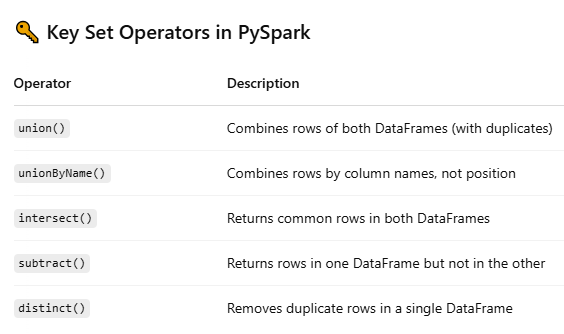

In [5]:
data1 = [
    (1, "Amit", "Delhi"),
    (2, "Priya", "Mumbai"),
    (3, "Rahul", "Kolkata")
]

data2 = [
    (3, "Rahul", "Kolkata"),
    (4, "Sneha", "Bangalore"),
    (5, "Ravi", "Chennai")
]

df1 = spark.createDataFrame(data1, ["id", "name", "city"])
df2 = spark.createDataFrame(data2, ["id", "name", "city"])

In [6]:
df1.show()
df2.show()

+---+-----+-------+
| id| name|   city|
+---+-----+-------+
|  1| Amit|  Delhi|
|  2|Priya| Mumbai|
|  3|Rahul|Kolkata|
+---+-----+-------+

+---+-----+---------+
| id| name|     city|
+---+-----+---------+
|  3|Rahul|  Kolkata|
|  4|Sneha|Bangalore|
|  5| Ravi|  Chennai|
+---+-----+---------+



## 1️⃣ union() – Combine Rows


**union() stacks two DataFrames vertically.**

**Columns must be in the same order and number.**

In [ ]:
# Synatx
df1.union(df2)

# column names and no. of columns should be same in both dataframe
# duplicates are not allowed
# unique records
# column sequence(index) should be ssame

In [7]:
df1.union(df2).show()

+---+-----+---------+
| id| name|     city|
+---+-----+---------+
|  1| Amit|    Delhi|
|  2|Priya|   Mumbai|
|  3|Rahul|  Kolkata|
|  3|Rahul|  Kolkata|
|  4|Sneha|Bangalore|
|  5| Ravi|  Chennai|
+---+-----+---------+



In [8]:
df1.union(df2).distinct().show()

+---+-----+---------+
| id| name|     city|
+---+-----+---------+
|  1| Amit|    Delhi|
|  2|Priya|   Mumbai|
|  3|Rahul|  Kolkata|
|  4|Sneha|Bangalore|
|  5| Ravi|  Chennai|
+---+-----+---------+



### UnionAll

In [ ]:
# syntax
df1.unionAll(df2)

# Column names and no. of columns should be same
### duplicates allowed
# column sequence should be same

In [9]:
df1.unionAll(df2).show()

+---+-----+---------+
| id| name|     city|
+---+-----+---------+
|  1| Amit|    Delhi|
|  2|Priya|   Mumbai|
|  3|Rahul|  Kolkata|
|  3|Rahul|  Kolkata|
|  4|Sneha|Bangalore|
|  5| Ravi|  Chennai|
+---+-----+---------+



## 2️⃣ unionByName() – Safer Column Match

**Safer to use when column names match but order doesn't.**

**Prevents mistakes due to column mismatches.**

In [10]:
data = [
    (1, "Delhi", "Amit"),
    (2, "Mumbai", "Priya"),
    (3, "Kolkata", "Rahul")
]


columns = ['id', 'city', 'name']

df5 = spark.createDataFrame(data, columns)
df5.show()

+---+-------+-----+
| id|   city| name|
+---+-------+-----+
|  1|  Delhi| Amit|
|  2| Mumbai|Priya|
|  3|Kolkata|Rahul|
+---+-------+-----+



In [12]:
df6 = df1.union(df5)
df6.show()

+---+-------+-------+
| id|   name|   city|
+---+-------+-------+
|  1|   Amit|  Delhi|
|  2|  Priya| Mumbai|
|  3|  Rahul|Kolkata|
|  1|  Delhi|   Amit|
|  2| Mumbai|  Priya|
|  3|Kolkata|  Rahul|
+---+-------+-------+



In [13]:
df1.unionByName(df5).show()

+---+-----+-------+
| id| name|   city|
+---+-----+-------+
|  1| Amit|  Delhi|
|  2|Priya| Mumbai|
|  3|Rahul|Kolkata|
|  1| Amit|  Delhi|
|  2|Priya| Mumbai|
|  3|Rahul|Kolkata|
+---+-----+-------+



In [ ]:
df3 = df2.drop(df2.city)
df3.show()

+---+-----+
| id| name|
+---+-----+
|  3|Rahul|
|  4|Sneha|
|  5| Ravi|
+---+-----+



## 3️⃣ intersect() – Common Rows


**Only returns identical rows present in both DataFrames.**

In [14]:
# set operator
# intersect

df1.intersect(df2).show()


+---+-----+-------+
| id| name|   city|
+---+-----+-------+
|  3|Rahul|Kolkata|
+---+-----+-------+



In [ ]:
# join

df1.join(df2, df1.id == df2.id, 'inner').show()

+---+-----+-------+---+-----+-------+
| id| name|   city| id| name|   city|
+---+-----+-------+---+-----+-------+
|  3|Rahul|Kolkata|  3|Rahul|Kolkata|
+---+-----+-------+---+-----+-------+



## 4️⃣ subtract() – Difference

**Returns rows from one DataFrame that are not in the other.**

In [ ]:
df1.subtract(df2).show()  # records available in df1 but not in df2

df2.subtract(df1).show()  # records available in df2 but not in df1


+---+-----+------+
| id| name|  city|
+---+-----+------+
|  2|Priya|Mumbai|
|  1| Amit| Delhi|
+---+-----+------+

+---+-----+---------+
| id| name|     city|
+---+-----+---------+
|  4|Sneha|Bangalore|
|  5| Ravi|  Chennai|
+---+-----+---------+



## 5️⃣ distinct() – Remove Duplicates

**After combining datasets, use distinct() to remove duplicate rows.**

In [ ]:
df1.union(df2).distinct().show()


+---+-----+---------+
| id| name|     city|
+---+-----+---------+
|  1| Amit|    Delhi|
|  2|Priya|   Mumbai|
|  3|Rahul|  Kolkata|
|  4|Sneha|Bangalore|
|  5| Ravi|  Chennai|
+---+-----+---------+



# Real-World Use Cases

**union() → Combine monthly sales records**

**intersect() → Find students present in both Class A and Class B**

**subtract() → Employees who left the company**

**distinct() → Remove duplicate transactions**

## PySpark Union and UnionAll Explained

In [18]:

import pyspark
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName('SparkByExamples.com').getOrCreate()

simpleData = [("James","Sales","NY",90000,34,10000), \
    ("Michael","Sales","NY",86000,56,20000), \
    ("Robert","Sales","CA",81000,30,23000), \
    ("Maria","Finance","CA",90000,24,23000) \
  ]

columns= ["employee_name","department","state","salary","age","bonus"]
df1 = spark.createDataFrame(data = simpleData, schema = columns)
df1.printSchema()
df1.show(truncate=False)


root
 |-- employee_name: string (nullable = true)
 |-- department: string (nullable = true)
 |-- state: string (nullable = true)
 |-- salary: long (nullable = true)
 |-- age: long (nullable = true)
 |-- bonus: long (nullable = true)

+-------------+----------+-----+------+---+-----+
|employee_name|department|state|salary|age|bonus|
+-------------+----------+-----+------+---+-----+
|James        |Sales     |NY   |90000 |34 |10000|
|Michael      |Sales     |NY   |86000 |56 |20000|
|Robert       |Sales     |CA   |81000 |30 |23000|
|Maria        |Finance   |CA   |90000 |24 |23000|
+-------------+----------+-----+------+---+-----+



In [19]:

simpleData2 = [("James","Sales","NY",90000,34,10000), \
    ("Maria","Finance","CA",90000,24,23000), \
    ("Jen","Finance","NY",79000,53,15000), \
    ("Jeff","Marketing","CA",80000,25,18000), \
    ("Kumar","Marketing","NY",91000,50,21000) \
  ]
columns2= ["employee_name","department","state","salary","age","bonus"]

df2 = spark.createDataFrame(data = simpleData2, schema = columns2)

df2.printSchema()
df2.show(truncate=False)


root
 |-- employee_name: string (nullable = true)
 |-- department: string (nullable = true)
 |-- state: string (nullable = true)
 |-- salary: long (nullable = true)
 |-- age: long (nullable = true)
 |-- bonus: long (nullable = true)

+-------------+----------+-----+------+---+-----+
|employee_name|department|state|salary|age|bonus|
+-------------+----------+-----+------+---+-----+
|James        |Sales     |NY   |90000 |34 |10000|
|Maria        |Finance   |CA   |90000 |24 |23000|
|Jen          |Finance   |NY   |79000 |53 |15000|
|Jeff         |Marketing |CA   |80000 |25 |18000|
|Kumar        |Marketing |NY   |91000 |50 |21000|
+-------------+----------+-----+------+---+-----+



# Union

** Merge two or more DataFrames using union**

**Dataframe union() – union() method of the DataFrame is used to merge two DataFrame’s of the same structure/schema. If schemas are not the same it returns an error.**

In [ ]:
unionDF = df.union(df2)
unionDF.show()

+-------------+----------+-----+------+---+-----+
|employee_name|department|state|salary|age|bonus|
+-------------+----------+-----+------+---+-----+
|        James|     Sales|   NY| 90000| 34|10000|
|      Michael|     Sales|   NY| 86000| 56|20000|
|       Robert|     Sales|   CA| 81000| 30|23000|
|        Maria|   Finance|   CA| 90000| 24|23000|
|        James|     Sales|   NY| 90000| 34|10000|
|        Maria|   Finance|   CA| 90000| 24|23000|
|          Jen|   Finance|   NY| 79000| 53|15000|
|         Jeff| Marketing|   CA| 80000| 25|18000|
|        Kumar| Marketing|   NY| 91000| 50|21000|
+-------------+----------+-----+------+---+-----+



## unionAll

** DataFrame unionAll() – unionAll() is deprecated since Spark “2.0.0” version and replaced with union().**

In [ ]:
unionAllDF = df.unionAll(df2)
unionAllDF.show(truncate=False)

+-------------+----------+-----+------+---+-----+
|employee_name|department|state|salary|age|bonus|
+-------------+----------+-----+------+---+-----+
|James        |Sales     |NY   |90000 |34 |10000|
|Michael      |Sales     |NY   |86000 |56 |20000|
|Robert       |Sales     |CA   |81000 |30 |23000|
|Maria        |Finance   |CA   |90000 |24 |23000|
|James        |Sales     |NY   |90000 |34 |10000|
|Maria        |Finance   |CA   |90000 |24 |23000|
|Jen          |Finance   |NY   |79000 |53 |15000|
|Jeff         |Marketing |CA   |80000 |25 |18000|
|Kumar        |Marketing |NY   |91000 |50 |21000|
+-------------+----------+-----+------+---+-----+



## Merge without Duplicates
### Since the union() method returns all rows without distinct records, we will use the distinct() function to return just one record when duplicate exists.

In [ ]:
disDF = df.union(df2).distinct()

disDF.show()

+-------------+----------+-----+------+---+-----+
|employee_name|department|state|salary|age|bonus|
+-------------+----------+-----+------+---+-----+
|        James|     Sales|   NY| 90000| 34|10000|
|      Michael|     Sales|   NY| 86000| 56|20000|
|        Maria|   Finance|   CA| 90000| 24|23000|
|       Robert|     Sales|   CA| 81000| 30|23000|
|        Kumar| Marketing|   NY| 91000| 50|21000|
|          Jen|   Finance|   NY| 79000| 53|15000|
|         Jeff| Marketing|   CA| 80000| 25|18000|
+-------------+----------+-----+------+---+-----+



# PySpark Merge Two DataFrames with Different Columns

In [20]:
#Create DataFrame df1 with columns name,dept & age
data = [("James","Sales",34), ("Michael","Sales",56), \
    ("Robert","Sales",30), ("Maria","Finance",24) ]
columns= ["name","dept","age"]
df1 = spark.createDataFrame(data = data, schema = columns)
df1.printSchema()

#Create DataFrame df1 with columns name,dep,state & salary
data2=[("James","Sales","NY",9000),("Maria","Finance","CA",9000), \
    ("Jen","Finance","NY",7900),("Jeff","Marketing","CA",8000)]
columns2= ["name","dept","state","salary"]
df2 = spark.createDataFrame(data = data2, schema = columns2)
df2.printSchema()

root
 |-- name: string (nullable = true)
 |-- dept: string (nullable = true)
 |-- age: long (nullable = true)

root
 |-- name: string (nullable = true)
 |-- dept: string (nullable = true)
 |-- state: string (nullable = true)
 |-- salary: long (nullable = true)



In [21]:
df1.show()
df2.show()

+-------+-------+---+
|   name|   dept|age|
+-------+-------+---+
|  James|  Sales| 34|
|Michael|  Sales| 56|
| Robert|  Sales| 30|
|  Maria|Finance| 24|
+-------+-------+---+

+-----+---------+-----+------+
| name|     dept|state|salary|
+-----+---------+-----+------+
|James|    Sales|   NY|  9000|
|Maria|  Finance|   CA|  9000|
|  Jen|  Finance|   NY|  7900|
| Jeff|Marketing|   CA|  8000|
+-----+---------+-----+------+



In [28]:
for column in df1.columns:
  if column not in df2.columns:
    print(column)

age


In [ ]:
a = [column for column in df1.columns if column not in df2.columns]

In [ ]:
lst = ['state','salary']

In [ ]:
for column in [column for column in df1.columns if column not in df2.columns]:
  df2 = df2.withColumn(column, lit(None))

**Now add missing columns ‘state‘ and ‘salary‘ to df1 and ‘age‘ to df2 with null values.**



In [29]:
#Add missing columns 'state' & 'salary' to df1
from pyspark.sql.functions import lit

for column in [column for column in df2.columns if column not in df1.columns]:
    df1 = df1.withColumn(column, lit(None))

#Add missing column 'age' to df2
for column in [column for column in df1.columns if column not in df2.columns]:
    df2 = df2.withColumn(column, lit(None))

In [30]:
df1.show()
df2.show()

+-------+-------+---+-----+------+
|   name|   dept|age|state|salary|
+-------+-------+---+-----+------+
|  James|  Sales| 34| NULL|  NULL|
|Michael|  Sales| 56| NULL|  NULL|
| Robert|  Sales| 30| NULL|  NULL|
|  Maria|Finance| 24| NULL|  NULL|
+-------+-------+---+-----+------+

+-----+---------+-----+------+----+
| name|     dept|state|salary| age|
+-----+---------+-----+------+----+
|James|    Sales|   NY|  9000|NULL|
|Maria|  Finance|   CA|  9000|NULL|
|  Jen|  Finance|   NY|  7900|NULL|
| Jeff|Marketing|   CA|  8000|NULL|
+-----+---------+-----+------+----+



**Now merge/union the DataFrames using unionByName().**


**In other words, unionByName() is used to merge two DataFrame’s by column names instead of by position.**

In [31]:
#Finally join two dataframe's df1 & df2 by name
combined_df = df1.unionByName(df2)
combined_df.show()

+-------+---------+----+-----+------+
|   name|     dept| age|state|salary|
+-------+---------+----+-----+------+
|  James|    Sales|  34| NULL|  NULL|
|Michael|    Sales|  56| NULL|  NULL|
| Robert|    Sales|  30| NULL|  NULL|
|  Maria|  Finance|  24| NULL|  NULL|
|  James|    Sales|NULL|   NY|  9000|
|  Maria|  Finance|NULL|   CA|  9000|
|    Jen|  Finance|NULL|   NY|  7900|
|   Jeff|Marketing|NULL|   CA|  8000|
+-------+---------+----+-----+------+



# Questions

In [ ]:
'''What is the output of df1.intersect(df2) if there are no common rows?

✅ Answer:
It will return an empty DataFrame with the same schema.'''

In [ ]:
'''What will happen if two DataFrames have duplicate rows and you perform union()?
✅ Answer:

union() will include all duplicates.

To remove duplicates, chain .distinct() after the union:'''

In [ ]:
df1.union(df2).distinct()


DataFrame[id: bigint, name: string, city: string]

In [ ]:
''' What is the output of df1.intersect(df2) if there are no common rows?
✅ Answer:

It will return an empty DataFrame with the same schema.'''

In [ ]:
''' What is the difference between union() and unionByName() in PySpark?
✅ Answer:

union() combines two DataFrames by position. Column order must match exactly.

unionByName() combines by column names, so column order can differ.

'''

In [ ]:
'''When would you use intersect() in PySpark?
✅ Answer:

Use intersect() when you want to find common rows between two DataFrames.

It returns only the exactly matching rows (all columns).'''

In [ ]:
'''Can you perform a union of two DataFrames with different schemas?
✅ Answer:

No, union() will throw an error if schemas (number and type of columns) don’t match.

Use unionByName() with allowMissingColumns=True (from Spark 3.1+) to handle slight mismatches.'''

In [ ]:
'''How do you find records that are present in one DataFrame but not in another?
✅ Answer:

Use the subtract() function.'''

In [ ]:
df1.subtract(df2)  # Returns rows in df1 but not in df2

DataFrame[id: bigint, name: string, city: string]